<a href="https://colab.research.google.com/github/Faisaleka21/Data_Science26/blob/main/UTS_DS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [4]:
# 1 baca dataset
df = pd.read_csv('https://raw.githubusercontent.com/Faisaleka21/Data_Science26/refs/heads/main/Data_Set/Dataset.csv', encoding='latin1')

Soal :    

1. Silahkan lakukan eksplorasi awal untuk mengetahui struktur, jumlah data, tipe variabel, missing values, dan statistik deskriptif. Kemudian analisislah apakah seluruh variable dapat
langsung digunakan? Jelaskan potensi masalah kualitas data dan dampaknya terhadap hasil analisis
2. Berdasarkan temuan soal (a) maka lakukanlah preprocessing yang memang diperlukan. Dokumentasikan setiap perubahan dan alasannya. Kemudian analisislah apakah teknik preprocessing yang dipilih sesuai dengan karakteristik data? Apa risiko jika
data diproses tanpa pemeriksaan awal?
3. Lakukan analisis terhadap distribusi skor GHI, nilai minimum dan maksimum, serta kemungkinan outlier menggunakan statistik deskriptif, histogram, dan boxplot. Dan menurut anda, apakah distribusi data menunjukkan kesenjangan skor antarnegara? Bagaimana nilai ekstrem memengaruhi interpretasi data?
4. Buatlah minimal tiga visualisasi untuk menjelaskan kondisi kelaparan global. Pilih grafik sesuai karakteristik
dan ketersediaan data, misalnya perbandingan antarnegara / distribusi skor / tren antarperiode. Kemudian jelaskan alasan pemilihan grafik, pola yang ditemukan, dan informasi yang tidak dapat dijelaskan oleh grafik tersebut
5. Ketika ada mahasiswa menuliskan:
“Negara dengan skor GHI paling tinggi pasti mengalami
kondisi kelaparan yang terus memburuk setiap tahun. Oleh
karena itu, negara tersebut harus menjadi prioritas utama
dalam semua kebijakan penanganan kelaparan” Menurut anda, apakah kesimpulan tersebut sepenuhnya dapat dibenarkan berdasarkan dataset? Gunakan hasil analisis sebelumnya untuk menjelaskan perbedaan antara kondisi pada satu periode, perubahan antarperiode, dan rekomendasi kebijakan

In [21]:
df = df[["Rank in 2022", "Country", "2000" , "2007", "2014", "2022", "Absolute change","Percent change"]]
display(df.head())

,Rank in 2022,Country,2000,2007,2014,2022,Absolute change,Percent change
0,NaN,NaN,NaN,NaN,NaN,NaN,since 2014,since 2014
1,1.0,Belarus,<5,<5,<5,<5,0,0
2,1.0,Bosnia and Herzegovina,9.3,6.6,<5,<5,0,0
3,1.0,Chile,<5,<5,<5,<5,0,0
4,1.0,China,13.3,7.8,<5,<5,0,0


In [6]:
df.shape

(130, 8)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 130 entries, 0 to 129
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Rank in 2022     129 non-null    float64
 1   Country          129 non-null    object 
 2   2000             129 non-null    object 
 3   2007             129 non-null    object 
 4   2014             129 non-null    object 
 5   2022             129 non-null    object 
 6   Absolute change  130 non-null    object 
 7   Percent change   130 non-null    object 
dtypes: float64(1), object(7)
memory usage: 8.3+ KB


In [8]:
df.isna().sum()

,0
Rank in 2022,1
Country,1
2000,1
2007,1
2014,1
2022,1
Absolute change,0
Percent change,0


In [9]:
# statistik deskriptif
display(df.describe(include='all'))

,Rank in 2022,Country,2000,2007,2014,2022,Absolute change,Percent change
count,129.000000,129,129,129,129,129,130,130
unique,NaN,128,105,97,90,91,56,92
top,NaN,Congo,99,<5,<5,<5,0,0
freq,NaN,2,10,9,15,17,27,27
mean,63.372093,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,38.372164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,32.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,64.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,97.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Jawaban No 1:
---
Jumlah data terdiri dari 130 data,

| Variabel | Type Dataa | missing value |
| :---: | :---: | :---: |
| Rank in 2022	| float64 | 1 |
| Country| object | 1 |
| 2000| object | 1 |
| 2007| object | 1 |
| 2014| object | 1 |
| 2022| object | 1 |
| Absolute change| object | 0 |
| Percent change| object | 0 |

seluruh variabel tidak dapat langsung digunakan, karena masih terdapat isiannya yang masih unik dan perlu dilakukannya pembersihan dalam data tersebut. Untuk masalah kualitas data yaitu adanya nilai yang kososng pada baris 0=NAN, type data mulai dari kolom Country sampai Percent Change sedikit mencurigakan karena isi dari variabel tertentu berupa angka atau type datanya float64. Dan dampaknya yaitu perhitungannya menjadi gagal dan hasilnya tidak sesuai yang diinginkan.

In [10]:
# 2. Preprocessing & membersihkan dataset GHI
# Menghapus baris kosong/metadata di baris pertama jika ada
df_clean = df.dropna(subset=['Country']).copy()

# Mengganti nilai '<5' menjadi nilai numerik estimasi (misal 2.5) agar bisa diolah secara statistik
kolom_tahun = ['2000', '2007', '2014', '2022']
for col in kolom_tahun:
    df_clean[col] = df_clean[col].astype(str).str.replace('<5', '2.5')
    # Mengubah nilai placeholder string non-numerik lainnya menjadi NaN
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# Menghapus data yang seluruh tahunnya kosong
df_clean = df_clean.dropna(subset=kolom_tahun, how='all')

# # Memisahkan data untuk dianalisis (Train/Test Split)
# train, test = train_test_split(df_clean, test_size=0.2, random_state=42)
# display(train.head())

In [14]:
# 4. Mengisi sisa missing values dengan nilai median masing-masing kolom tahun
for col in kolom_tahun:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)

In [15]:
# Cek hasil akhir setelah preprocessing
df_clean.info()
print("\nJumlah missing values setelah preprocessing:")
print(df_clean[kolom_tahun].isnull().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 129 entries, 1 to 129
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Rank in 2022     129 non-null    float64
 1   Country          129 non-null    object 
 2   2000             129 non-null    float64
 3   2007             129 non-null    float64
 4   2014             129 non-null    float64
 5   2022             129 non-null    float64
 6   Absolute change  129 non-null    object 
 7   Percent change   129 non-null    object 
dtypes: float64(5), object(3)
memory usage: 9.1+ KB

Jumlah missing values setelah preprocessing:
2000    0
2007    0
2014    0
2022    0
dtype: int64


## Jawaban No 2:
---
berdasarkan hasil temuan pada no 1 yaitu teknik prepocessing sudah sesuai dengan karakteristik data GHI karena nilai yang <5 udah diubah menjadi nilai estimasi 2.5 sehingga data yang <5 tidak perlu dihapus.

Jika data diproses tanpa pemeriksaan awal maka perhitungan statistik akan gagal karena terdapat type data, data unique, dan ada missing value sehingga hasil dari perhitungan ini menjadi menyesatkan.

In [18]:
# Statistik deskriptif untuk melihat min, max, mean, median, dan kuartil
display(df_clean[kolom_tahun].describe())

,2000,2007,2014,2022
count,129.000000,129.000000,129.000000,129.000000
mean,30.035659,25.082946,21.348837,15.029457
std,24.801518,22.831924,22.603405,10.073553
min,0.000000,0.000000,2.500000,2.500000
25%,11.600000,10.100000,7.400000,6.900000
50%,23.800000,19.200000,15.400000,13.200000
75%,40.300000,32.100000,26.500000,20.700000
max,99.000000,99.000000,99.000000,45.100000


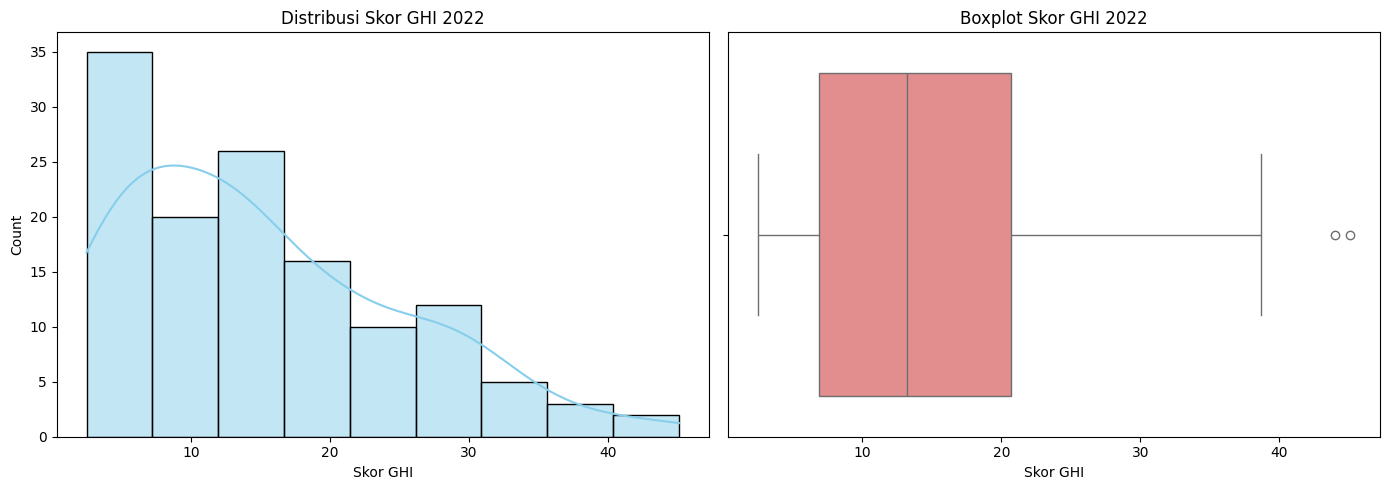

In [19]:
# Visualisasi Histogram & Boxplot distribusi skor GHI 2022
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik 1: Histogram Skor GHI 2022
sns.histplot(data=df_clean, x="2022", kde=True, ax=axes[0], color='skyblue')
axes[0].set_title("Distribusi Skor GHI 2022")
axes[0].set_xlabel("Skor GHI")

# Grafik 2: Boxplot Skor GHI 2022
sns.boxplot(data=df_clean, x="2022", ax=axes[1], color='lightcoral')
axes[1].set_title("Boxplot Skor GHI 2022")
axes[1].set_xlabel("Skor GHI")

plt.tight_layout()
plt.show()

## Jawaban No 3:
---
Dari distribusi skor GHI di tahun 2022 bahwa trendnya turun ke kanan. untuk nilai min 2,5 sampai dengan nilai maxnya 45,1, serta dengan meannya 15. Dari hasil tersebut memang benar terdapat kesenjangan antarnegara dimana jika dilihat dari Distribusi skor GHI 2022 menandakan bahwa di banyaknya negara (count)  tingkat kelaparannya (skor GHI) sangat rendah dan sedikit negara tetapi tingkat kelaparannya sangat tinggi.

Nilai ektrem memengerahui interpretasi karena dapat menarik nilai rata rata naik dibandingkan mediannya yaitu 13,2 shingga tidak mewakilikan kondisi sebagian besar suatu negara, jadi melihat rata-rata tanpa melihat nilai ektrem menyebabkan kondsi kelaparan global yang tinggi daripada kosisi mayoritas negara sebenarnya.

/tmp/ipykernel_2186/720400177.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_2022, x='2022', y='Country', palette='Reds_r')


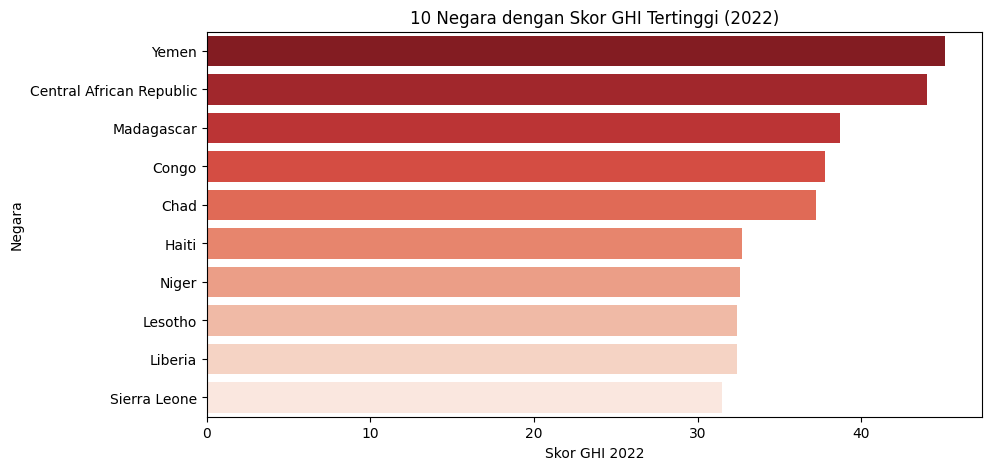

In [23]:
# 1. Bar Chart: 10 Negara dengan Skor GHI Tertinggi di 2022 (Perbandingan Antarnegara)
top10_2022 = df_clean.nlargest(10, '2022')
plt.figure(figsize=(10, 5))
sns.barplot(data=top10_2022, x='2022', y='Country', palette='Reds_r')
plt.title('10 Negara dengan Skor GHI Tertinggi (2022)')
plt.xlabel('Skor GHI 2022')
plt.ylabel('Negara')
plt.show()


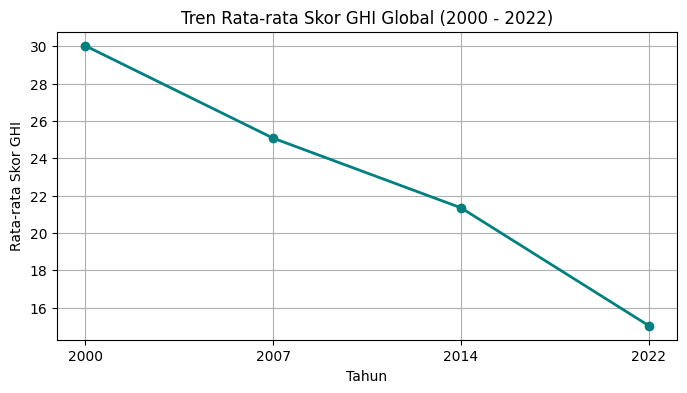

In [24]:

# 2. Line Chart: Tren Rata-rata Skor GHI Global (2000 - 2022)
mean_trend = df_clean[kolom_tahun].mean()
plt.figure(figsize=(8, 4))
plt.plot(mean_trend.index, mean_trend.values, marker='o', linewidth=2, color='teal')
plt.title('Tren Rata-rata Skor GHI Global (2000 - 2022)')
plt.xlabel('Tahun')
plt.ylabel('Rata-rata Skor GHI')
plt.grid(True)
plt.show()

/tmp/ipykernel_2186/684788934.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_melted, x='Tahun', y='Skor_GHI', palette='Set2')


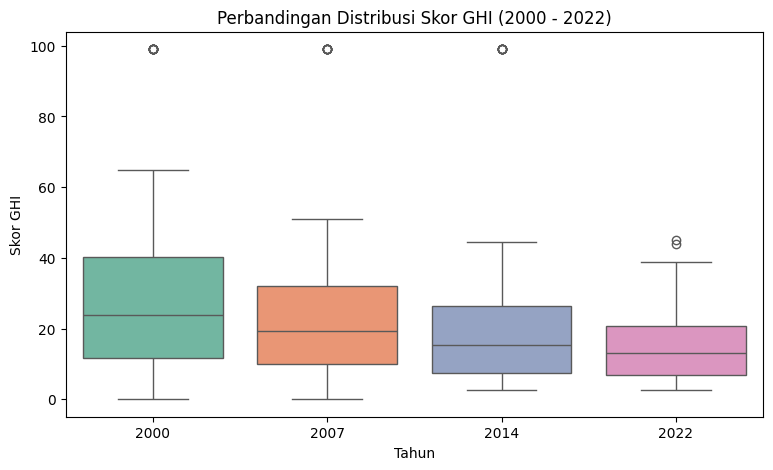

In [25]:

# 3. Boxplot: Perbandingan Distribusi Skor GHI Antarperiode
df_melted = df_clean.melt(id_vars=['Country'], value_vars=kolom_tahun, var_name='Tahun', value_name='Skor_GHI')
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_melted, x='Tahun', y='Skor_GHI', palette='Set2')
plt.title('Perbandingan Distribusi Skor GHI (2000 - 2022)')
plt.xlabel('Tahun')
plt.ylabel('Skor GHI')
plt.show()

## Jawaban No 4:
---
- Bar Chart

ini digunakan karena mudah untuk melihat urutan peringkat dan skor antarnegar. Untuk pola yang ditemukan dalam bar chart ini yaitu menemukan top negara tertinggi yang tingkat kelaparannya tinggi. Untuk inforormasi yang tidak dijelaskan pada grafik ini yaitu tingkat kelaparan suatu negara dibebabkan oleh faktor tertentu.

- Line Chart

pada grafik ini dapat digunakan karena untuk melihat rend data dari waktu ke waktu, pada grafik ini pola yang bisa ditemukan yaitu melihat rata2 pada SKOR GHI dari tahun 2000-2022 yang terlihat turun yang menandakan bahwa tingkat kelaparan pada suatu negara sudah cukup teratasi. Untuk informasi yang tidak bisa dijelaskan pada grafik ini yaitu kondisi pada suatu masing-masing.


- Bocplot

garfik ini dipilih karena untuk melihat tingkat sebara data per periode sekaliguss. Untuk pola yang ditemukan pada grafik ini yaitu  posisi body candle dan garis tersebut semakin turun dan nilai extremnya juga ikut turun dari 100 menjadi ke 40an pada tahun 2022. Dan untuk informasi yang tidak bisa dijelaskan pada grafik ini yaitu nama-nama pada suatu negara tidak bisa dicantumkan serta jumlah penduduk yang terdampak kelaparan.



In [29]:
# Melihat tren historis 5 negara dengan skor GHI tertinggi di tahun 2022
top5_trend = df_clean.nlargest(5, '2022')[['Country', '2000', '2007', '2014', '2022']]
display(top5_trend)

,Country,2000,2007,2014,2022
125,Yemen,41.3,38.4,41.7,45.1
124,Central African Republic,48.8,46.8,44.6,44.0
123,Madagascar,42.5,37.2,37.3,38.7
122,Congo,48.0,43.2,38.7,37.8
121,Chad,50.7,49.0,40.7,37.2


## Jawaban No 5:
---
Kesimpulan tersebut tidak bisa dibenarkan berdasarkan dataset karena skor GHI tertinggi ada pada tahun 2022 yang hanya menunjukkan 1 periode aja, bukan terbukti semakin memburuk setiap tahunnya.

untuk dilihat berdasarkan periode daru output kode diatas menunjukkan bahwa pada tahun 2022 negara yamen skor GHInya paling tinggi, tetapi sebenarnyna pernah turun seblum naik lagi scorenya.

oleh karena untuk rekomendasi kebijakan tidak bisa dilihat pada 1 periode saja melainkan melihat dari trend perubahan perperiodenya.